In [11]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [12]:
df = pd.read_csv('Fashion_Retail_Sales_Cleaned_Transformed.csv')

In [13]:
df.shape

(4000, 36)

In [14]:
df.head()

,Order_ID,Order_Date,Order_Channel,Payment_Method,Customer_ID,Customer_Name,Gender,Age,Age_Group,Customer_Type,...,Order_Quarter,Profit,Profit_Margin_%,Order_Month,Sales_Category,Profit_Category,Customer_Order_Count,Product_Performance,Total_Units_Per_Order,Order_Size
0,ORD-2025-00001,2025-01-01,Website,UPI,CUST-0001,Nisha Kaur,Female,38,35-44,Occasional Customer,...,Q1,503.92,45.85,January,Medium Sales,Low Profit,2,High Performer,1.0,Small Order
1,ORD-2025-00002,2025-01-01,Website,UPI,CUST-0002,Aarav Krishnan,Male,20,18-24,One-Time Customer,...,Q1,179.64,17.28,January,Medium Sales,Low Profit,1,Average Performer,1.0,Small Order
2,ORD-2025-00003,2025-01-01,Mobile App,Cash on Delivery,CUST-0003,Pooja Arora,Female,18,18-24,Frequent Customer,...,Q1,327.08,26.02,January,Medium Sales,Low Profit,13,Average Performer,4.0,Medium Order
3,ORD-2025-00004,2025-01-01,Physical Store,Credit Card,CUST-0004,Vaishnavi Ghosh,Female,27,25-34,One-Time Customer,...,Q1,676.47,52.86,January,Medium Sales,Low Profit,1,Low Performer,3.0,Medium Order
4,ORD-2025-00005,2025-01-02,Physical Store,UPI,CUST-0005,Bhavna Mishra,Female,28,25-34,Occasional Customer,...,Q1,722.90,37.68,January,High Sales,Low Profit,3,Average Performer,2.0,Small Order


In [19]:
df.columns

Index(['Order_ID', 'Order_Date', 'Order_Channel', 'Payment_Method',
       'Customer_ID', 'Customer_Name', 'Gender', 'Age', 'Age_Group',
       'Customer_Type', 'Segment', 'Product_Category', 'Product_Name', 'Brand',
       'Size', 'Color', 'Units_Sold', 'Unit_Price', 'Discount_%',
       'Sales_Amount', 'Cost_Amount', 'City', 'State', 'Region',
       'Return_Status', 'Order_Year', 'Order_Quarter', 'Profit',
       'Profit_Margin_%', 'Order_Month', 'Sales_Category', 'Profit_Category',
       'Customer_Order_Count', 'Product_Performance', 'Total_Units_Per_Order',
       'Order_Size'],
      dtype='object')

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 36 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Order_ID               4000 non-null   object 
 1   Order_Date             4000 non-null   object 
 2   Order_Channel          4000 non-null   object 
 3   Payment_Method         4000 non-null   object 
 4   Customer_ID            4000 non-null   object 
 5   Customer_Name          4000 non-null   object 
 6   Gender                 4000 non-null   object 
 7   Age                    4000 non-null   int64  
 8   Age_Group              4000 non-null   object 
 9   Customer_Type          4000 non-null   object 
 10  Segment                4000 non-null   object 
 11  Product_Category       4000 non-null   object 
 12  Product_Name           4000 non-null   object 
 13  Brand                  4000 non-null   object 
 14  Size                   4000 non-null   object 
 15  Colo

In [23]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'])

In [25]:
df['Order_Date'].dtype

dtype('<M8[ns]')

## Sales Analysis

In [28]:
Total_Sales = df['Sales_Amount'].sum()
print(f'Total_Sales = {Total_Sales:0.2f}')

Total_Sales = 12230418.60


In [30]:
months = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October','November', 'December']

In [32]:
Monthly_Sales = df.groupby('Order_Month')['Sales_Amount'].sum()
Monthly_Sales = Monthly_Sales.reindex(months)
print(f'''Monthly_Sales = 

{Monthly_Sales}''')

Monthly_Sales = 

Order_Month
January       869432.00
February      826025.00
March        1033394.55
April         802252.60
May           678614.90
June         1001841.95
July         1189141.85
August        941542.45
September     855849.30
October      1478657.55
November     1441314.65
December     1112351.80
Name: Sales_Amount, dtype: float64


In [34]:
Product_Category_Sales = df.groupby('Product_Category')['Sales_Amount'].sum().sort_values(ascending = False)
print(f'''Product Category Sales = 

{Product_Category_Sales}''')

Product Category Sales = 

Product_Category
T-Shirts       1699795.20
Shoes          1588142.60
Shirts         1563866.65
Accessories    1434349.90
Sweatshirts    1370935.70
Trousers       1283444.15
Jeans          1253519.60
Jackets        1253426.90
Dresses         782937.90
Name: Sales_Amount, dtype: float64


In [36]:
Brand_Sales = df.groupby('Brand')['Sales_Amount'].sum().sort_values(ascending = False)
print(f'''Brand Sales = 

{Brand_Sales}''')

Brand Sales = 

Brand
ModeStreet     1673799.15
UrbanEdge      1643374.95
StyleCraft     1618855.75
VogueLine      1182090.35
StreetMode     1143785.55
ThreadLab      1080939.65
TrendAura      1037312.10
UrbanThread    1018855.55
FashionNest     942493.20
WearWorks       888912.35
Name: Sales_Amount, dtype: float64


In [38]:
Regional_Sales = df.groupby('Region')['Sales_Amount'].sum().sort_values(ascending = False)
print(f'''Regional Sales = 

{Regional_Sales}''')

Regional Sales = 

Region
West       4681881.85
South      4161239.95
North      2069288.55
East       1131906.70
Central     186101.55
Name: Sales_Amount, dtype: float64


In [40]:
Topten_products = df.groupby('Product_Name').agg(
    Product_Category = ('Product_Category','first'),
    Total_Sales = ('Sales_Amount','sum'))

Topten_products = Topten_products.nlargest(10, 'Total_Sales')
print(f'''Top 10 Product = 

{Topten_products.head(10)}''')

Top 10 Product = 

                  Product_Category  Total_Sales
Product_Name                                   
Casual Sneakers              Shoes    569750.35
Hoodie                 Sweatshirts    484638.75
Running Shoes                Shoes    483579.75
Polo T-Shirt              T-Shirts    472107.95
Linen Shirt                 Shirts    462873.70
Oversized T-Shirt         T-Shirts    459888.35
Casual Shirt                Shirts    443472.20
Bomber Jacket              Jackets    424913.20
Backpack               Accessories    407521.50
Cargo Trousers            Trousers    381934.25


In [42]:
Bottomten_products = Topten_products.tail(10).sort_values(by = 'Total_Sales')

print(f'''Bottom 10 Product = 

{Bottomten_products}''')

Bottom 10 Product = 

                  Product_Category  Total_Sales
Product_Name                                   
Cargo Trousers            Trousers    381934.25
Backpack               Accessories    407521.50
Bomber Jacket              Jackets    424913.20
Casual Shirt                Shirts    443472.20
Oversized T-Shirt         T-Shirts    459888.35
Linen Shirt                 Shirts    462873.70
Polo T-Shirt              T-Shirts    472107.95
Running Shoes                Shoes    483579.75
Hoodie                 Sweatshirts    484638.75
Casual Sneakers              Shoes    569750.35


## Profit Analysis

In [45]:
Total_Profit = df['Profit'].sum()
print(f'''Total Profit = {Total_Profit:0.2f}''')

Total Profit = 3448898.36


In [47]:
Monthly_Profit = df.groupby('Order_Month')['Profit'].sum()
Monthly_Profit = Monthly_Profit.reindex(months)
print(f'''Monthly Profit = 

{Monthly_Profit}''')

Monthly Profit = 

Order_Month
January      253007.24
February     225330.61
March        296530.89
April        282688.42
May          196161.63
June         275673.76
July         335892.08
August       283726.98
September    225187.23
October      425420.34
November     394206.29
December     255072.89
Name: Profit, dtype: float64


In [49]:
Category_Profit = df.groupby('Product_Category')['Profit'].sum().sort_values(ascending = False)
print(f'''Category Profit = 

{Category_Profit}''')

Category Profit = 

Product_Category
T-Shirts       558779.35
Accessories    541071.34
Shirts         470950.99
Sweatshirts    389919.25
Trousers       370620.50
Jeans          361134.19
Shoes          313894.59
Jackets        251086.37
Dresses        191441.78
Name: Profit, dtype: float64


In [51]:
Regional_Profit = df.groupby('Region')['Profit'].sum().sort_values(ascending = False)
print(f'''Regional Profit = 

{Regional_Profit}''')

Regional Profit = 

Region
West       1263477.22
South      1234303.73
North       579913.93
East        314087.54
Central      57115.94
Name: Profit, dtype: float64


In [53]:
Product_Profit = df.groupby('Product_Name').agg(
    Product_Category = ('Product_Category', 'first'),
    Total_Profit = ('Profit', 'sum')
)
print(f'''Regional Profit = 

{Regional_Profit}''')

Regional Profit = 

Region
West       1263477.22
South      1234303.73
North       579913.93
East        314087.54
Central      57115.94
Name: Profit, dtype: float64


In [55]:
Profit_Margin = (Total_Profit/Total_Sales) * 100
print(f'Profit_Margin = {Profit_Margin:0.2f}')

Profit_Margin = 28.20


### Monthly Sales Line Chart 

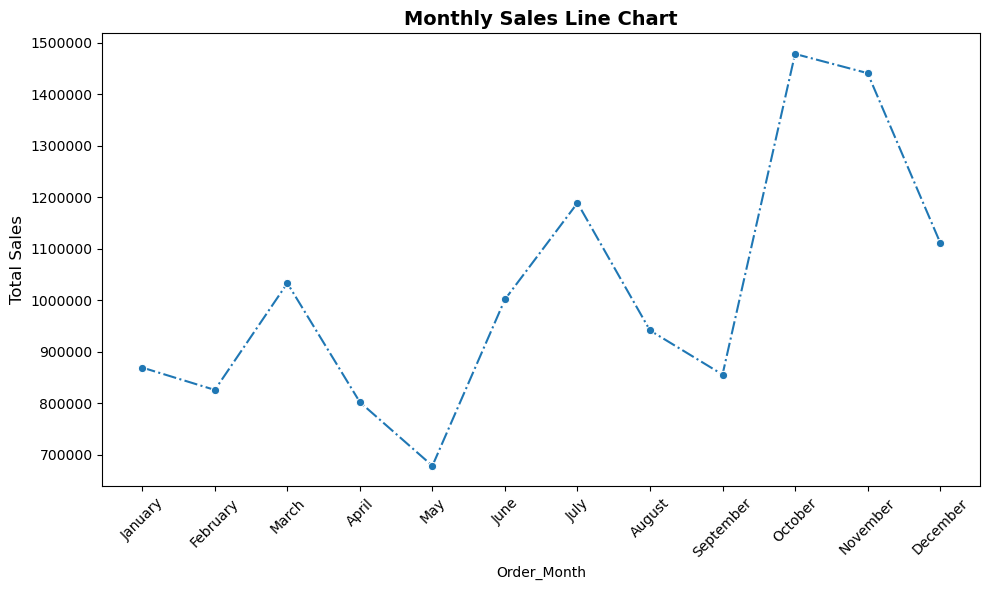

In [58]:
plt.figure(figsize = (10,6))
sns.lineplot(x = Monthly_Sales.index, y = Monthly_Sales.values, marker = 'o', linestyle = '-.')
plt.title('Monthly Sales Line Chart', fontsize = 14, fontweight = 'bold')
plt.ylabel('Total Sales', fontsize = 12)
plt.ticklabel_format(axis='y', style='plain')
plt.xticks(rotation = 45)
plt.tight_layout()
plt.savefig('Monthly_Sales_Line_Chart.png', dpi = 600)
plt.show()

### Category Sales Bar Char

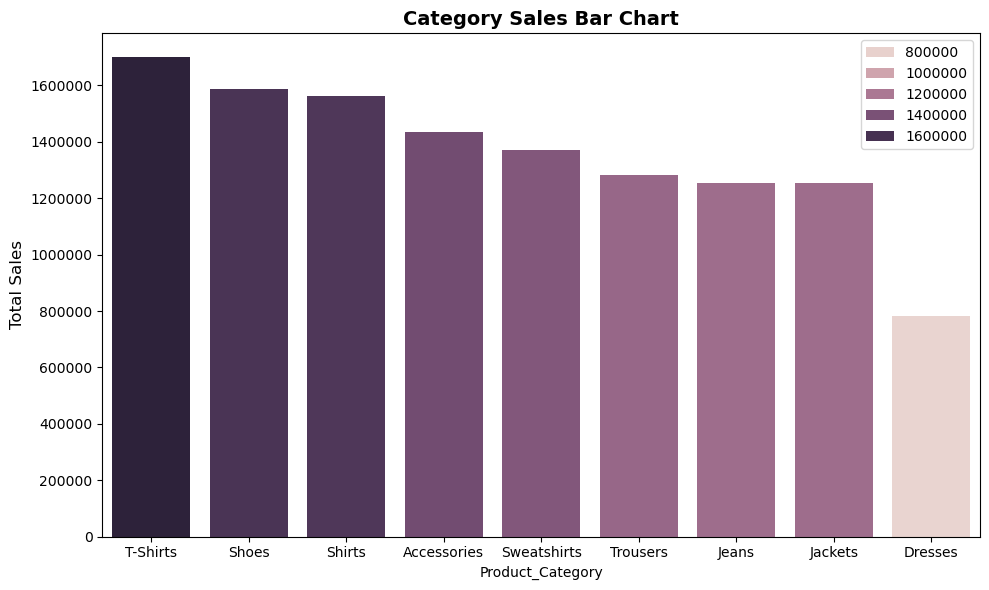

In [60]:
plt.figure(figsize = (10,6))

sns.barplot(x = Product_Category_Sales.index, y = Product_Category_Sales.values, hue = Product_Category_Sales.values)
plt.title('Category Sales Bar Chart', fontsize = 14, fontweight = 'bold')
plt.ylabel('Total Sales', fontsize = 12)
plt.ticklabel_format(axis='y', style='plain')
plt.tight_layout()
plt.savefig('Category_Sales_Bar_Chart.png', dpi = 600)
plt.show()

### Region Sales Bar Chart 

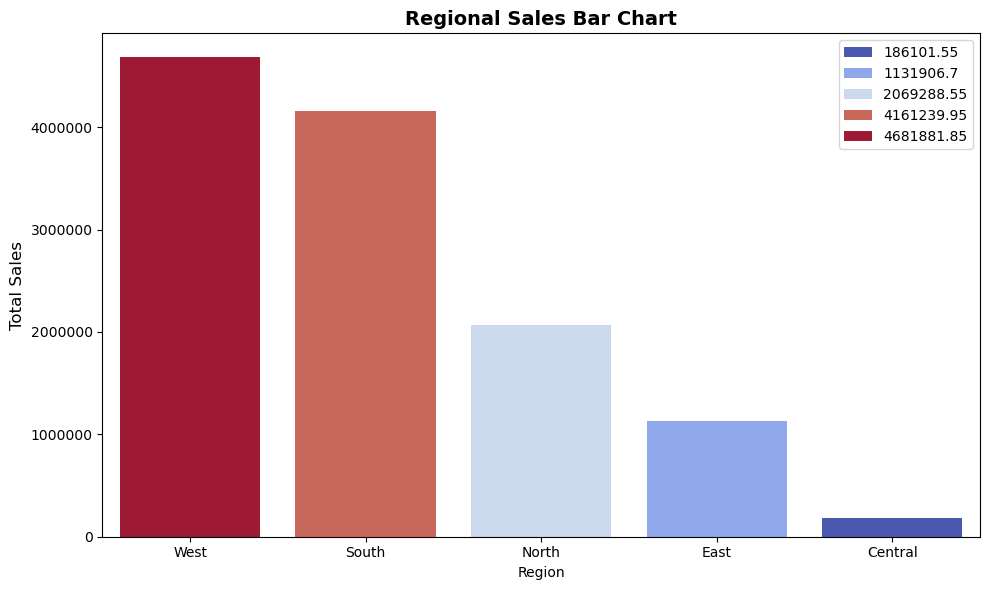

In [62]:
plt.figure(figsize = (10,6))

sns.barplot(x = Regional_Sales.index, y = Regional_Sales.values, hue = Regional_Sales.values,  palette='coolwarm')
plt.title('Regional Sales Bar Chart', fontsize = 14, fontweight = 'bold')
plt.ylabel('Total Sales', fontsize = 12)
plt.ticklabel_format(axis='y', style='plain')
plt.tight_layout()
plt.savefig('Regional_Sales_Bar_Chart.png', dpi = 600)
plt.show()

### Top Products Bar Chart

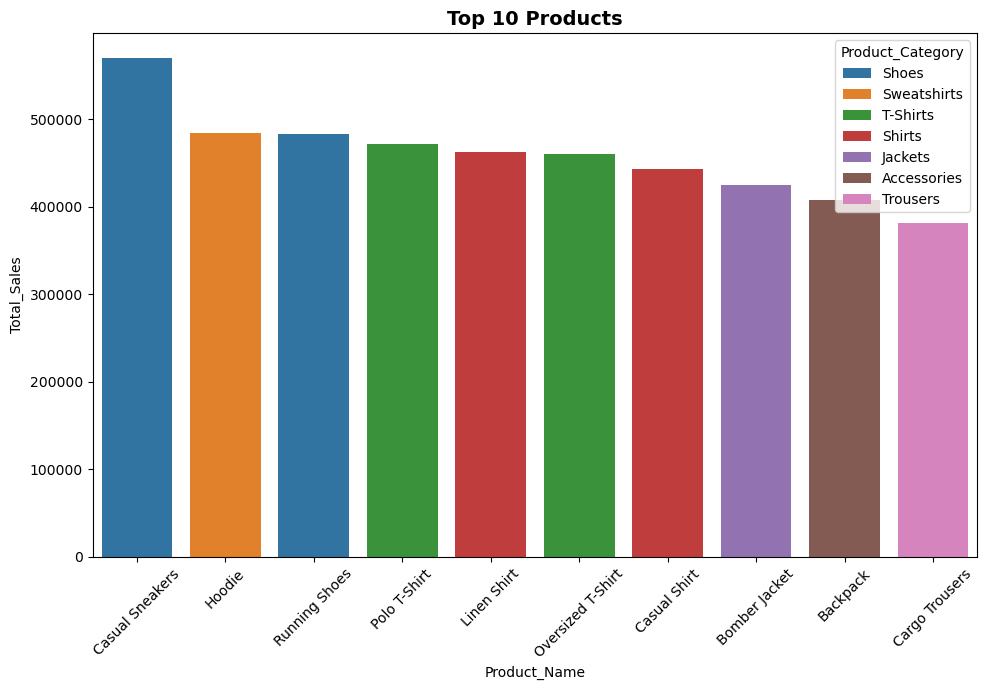

In [65]:
plt.figure(figsize = (10,7))

Topten_products = Topten_products.nlargest(10, 'Total_Sales')
sns.barplot(data = Topten_products, x = Topten_products.index, y = 'Total_Sales', hue = 'Product_Category')

plt.title('Top 10 Products', fontsize = 14, fontweight = 'bold')
plt.xticks(rotation = 45)
plt.tight_layout()
plt.savefig('Top10_Products_Bar_Chart.png', dpi = 600)
plt.show()

### Profit by Category 

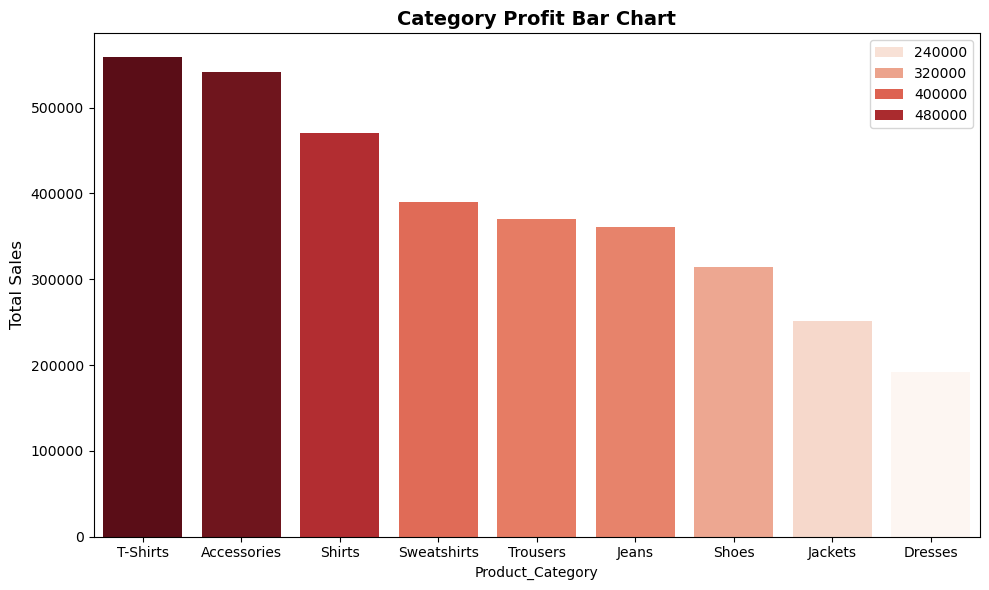

In [73]:
plt.figure(figsize = (10,6))

sns.barplot(x = Category_Profit.index, y = Category_Profit.values, hue = Category_Profit.values, palette = 'Reds')
plt.title('Category Profit Bar Chart', fontsize = 14, fontweight = 'bold')
plt.ylabel('Total Sales', fontsize = 12)
plt.ticklabel_format(axis='y', style='plain')
plt.tight_layout()
plt.savefig('Category_Profit_bar_Chart.png', dpi = 600)
plt.show()

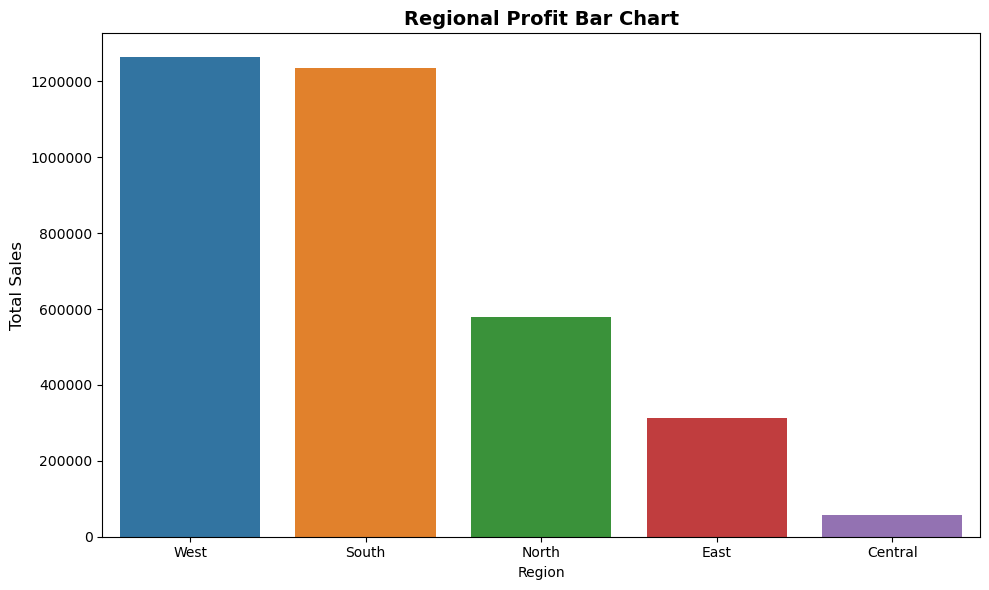

In [75]:
plt.figure(figsize = (10,6))

sns.barplot(x = Regional_Profit.index, y = Regional_Profit.values, hue = Regional_Profit.index)
plt.title('Regional Profit Bar Chart', fontsize = 14, fontweight = 'bold')
plt.ylabel('Total Sales', fontsize = 12)
plt.ticklabel_format(axis='y', style='plain')
plt.tight_layout()
plt.savefig('Regional_Profit_Bar_Chart.png', dpi = 600)
plt.show()

### Sales Distribution 

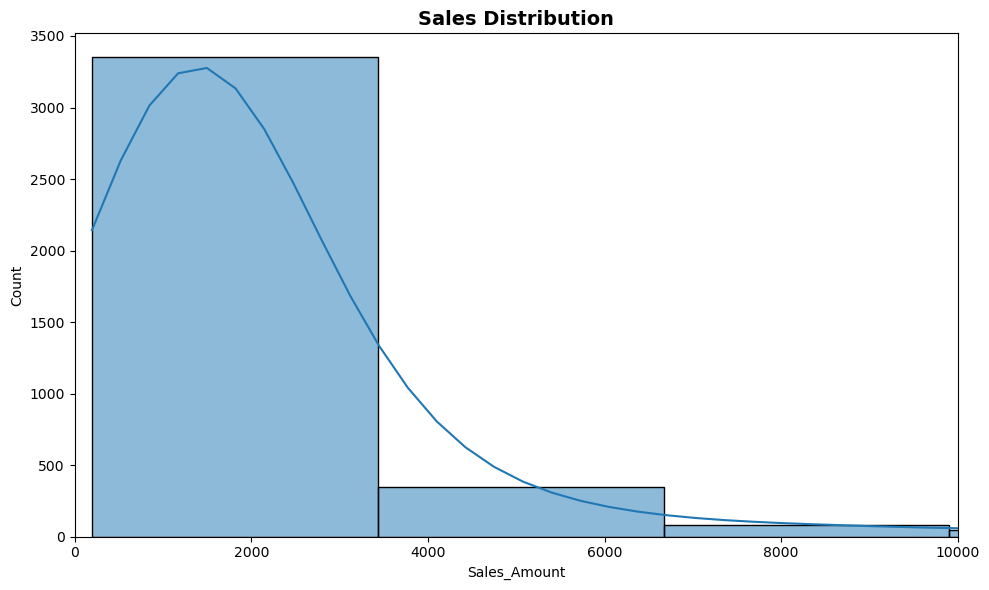

In [78]:
plt.figure(figsize = (10,6))
sns.histplot(data = df, x='Sales_Amount', bins = 20, kde=True)
plt.title('Sales Distribution', fontsize = 14, fontweight = 'bold')
plt.xlim(0, 10000)
plt.tight_layout()
plt.savefig('Sales_Distribution.png', dpi = 600)
plt.show()

In [80]:
Topten_products = Topten_products.nlargest(10, 'Total_Sales')
Topten_products

,Product_Category,Total_Sales
Product_Name,,
Casual Sneakers,Shoes,569750.35
Hoodie,Sweatshirts,484638.75
Running Shoes,Shoes,483579.75
Polo T-Shirt,T-Shirts,472107.95
Linen Shirt,Shirts,462873.70
Oversized T-Shirt,T-Shirts,459888.35
Casual Shirt,Shirts,443472.20
Bomber Jacket,Jackets,424913.20
Backpack,Accessories,407521.50
